# GMIA-NEXT ground-truth points — inspection

GMIA-NEXT (Kebede et al., 2026, v0) is a global 30 m map of irrigated cropland for the **2023/24 growing season**.

- Ground-truth points: [zenodo.org/records/20732681](https://zenodo.org/records/20732681) (local copy in `../GMIA-NEXT_GT/`)
- Maps (binary and probability): [zenodo.org/records/17627111](https://zenodo.org/records/17627111)

Field `irrigated`: 1 = irrigated, 0 = rainfed / non-irrigated. Field `Source`: the dataset each point comes from.


In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch
from scipy.spatial import cKDTree

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [2]:
ROOT = Path.cwd()
GMIA_DIR = ROOT.parent / "GMIA-NEXT_GT"
POINTS_FILE = GMIA_DIR / "GMIA-NEXT_GTPs_2024_v0_1" / "GMIA-NEXT_GTPs_2024_v0_1.shp"
COUNTRIES_FILE = GMIA_DIR / "WB_world_countries.geojson"

# Our survey (only used in Part B when the country is Morocco).
SURVEY_FILE = ROOT / "outputs" / "split" / "parcels_split.geojson"
WORLDCOVER_FILE = ROOT / "Morocco_data" / "ESA_LULC_2021" / "ESA_WorldCover_10m_2021.tif"

OUT_DIR = ROOT / "outputs" / "gmia"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Part B country (ISO 3166 alpha-3 code as in the World Bank boundaries, e.g. "MAR", "TUN").
COUNTRY_ISO = "MAR"
UTM = 32629   # metric CRS for Part B distances; UTM 29N suits Morocco (use 32632 for Tunisia)
BLOCK_KM = 20 # same block size as 2_split_train_test.ipynb

CLASS_NAMES = {1: "Irrigated", 0: "Rainfed / non-irrigated"}
CLASS_COLORS = {1: "#1f77b4", 0: "#d62728"}

def save(fig, name):
    path = OUT_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved {path.relative_to(ROOT)}")

# Part A — Global

## A1. Load

In [3]:
pts = gpd.read_file(POINTS_FILE, engine="pyogrio")
# Coordinates from the geometry itself (the long / lat columns are not reliable for every source, see A2).
pts["x"], pts["y"] = pts.geometry.x, pts.geometry.y
countries = gpd.read_file(COUNTRIES_FILE).to_crs(4326)
print(f"{len(pts):,} points, CRS {pts.crs}, columns {list(pts.columns)}")
pts.head()

601,972 points, CRS EPSG:4326, columns ['long', 'lat', 'irrigated', 'Source', 'geometry', 'x', 'y']


,long,lat,irrigated,Source,geometry,x,y
0,-37.889726,-4.620080,1,GMIE (Tian et al (2025)),POINT Z (-37.88973 -4.62008 0),-37.889726,-4.620080
1,-38.353378,-4.709295,1,GMIE (Tian et al (2025)),POINT Z (-38.35338 -4.70929 0),-38.353378,-4.709295
2,-38.313078,-4.719724,1,GMIE (Tian et al (2025)),POINT Z (-38.31308 -4.71972 0),-38.313078,-4.719724
3,-38.300657,-4.730934,1,GMIE (Tian et al (2025)),POINT Z (-38.30066 -4.73093 0),-38.300657,-4.730934
4,-37.867885,-4.733803,1,GMIE (Tian et al (2025)),POINT Z (-37.86788 -4.7338 0),-37.867885,-4.733803


## A2. Data quality

The README states **380,696 points (230,683 irrigated, 153,194 rainfed)**. The table below compares that with the file, and checks coordinates and duplicates. Duplicates are found on the point geometry, not on the `long` / `lat` columns, because one source has those columns set to 0.

In [4]:
same_xy = pts.duplicated(["x", "y"], keep=False)
xy_groups = pts[same_xy].groupby(["x", "y"])["irrigated"].nunique()
bad_cols = (pts["x"] - pts["long"]).abs().gt(1e-6) | (pts["y"] - pts["lat"]).abs().gt(1e-6)

quality = pd.Series({
    "points in file": len(pts),
    "points stated in README": 380_696,
    "irrigated in file": int((pts["irrigated"] == 1).sum()),
    "irrigated in README": 230_683,
    "rainfed in file": int((pts["irrigated"] == 0).sum()),
    "rainfed in README": 153_194,
    "missing geometry": int(pts.geometry.isna().sum()),
    "lat outside ±90 or long outside ±180": int(((pts["lat"].abs() > 90) | (pts["long"].abs() > 180)).sum()),
    "long / lat columns differ from geometry": int(bad_cols.sum()),
    "points sharing coordinates with another point": int(same_xy.sum()),
    "extra copies (duplicates beyond the first)": int(pts.duplicated(["x", "y"]).sum()),
    "locations with conflicting labels": int((xy_groups > 1).sum()),
}, name="value")
display(quality.to_frame())
print("Sources where long / lat differ from the geometry:")
print(pts.loc[bad_cols, "Source"].value_counts().to_string())
print("Example rows:")
pts.loc[bad_cols, ["long", "lat", "x", "y", "Source"]].head(3)

,value
points in file,601972
points stated in README,380696
irrigated in file,283352
irrigated in README,230683
rainfed in file,318620
rainfed in README,153194
missing geometry,0
lat outside ±90 or long outside ±180,0
long / lat columns differ from geometry,20658
points sharing coordinates with another point,51161


Sources where long / lat differ from the geometry:
Source
Souza et al (2020)    20658
Example rows:


,long,lat,x,y,Source
455910,0.0,0.0,-48.473438,-16.853389,Souza et al (2020)
455911,0.0,0.0,-45.915395,-18.267157,Souza et al (2020)
455912,0.0,0.0,-47.756313,-17.309104,Souza et al (2020)


Duplicates are removed for the rest of the notebook. Locations that carry both labels are dropped, since the label is uncertain there; for exact copies one point is kept.

In [5]:
conflict_xy = xy_groups[xy_groups > 1].index
is_conflict = pts.set_index(["x", "y"]).index.isin(conflict_xy)
clean = pts[~is_conflict].drop_duplicates(["x", "y"]).copy()
clean["class_name"] = clean["irrigated"].map(CLASS_NAMES)
print(f"Kept {len(clean):,} of {len(pts):,} points "
      f"(dropped {is_conflict.sum():,} conflicting and {len(pts) - is_conflict.sum() - len(clean):,} duplicate copies)")

# Where the duplicates come from.
dup_by_source = pd.DataFrame({
    "points": pts["Source"].value_counts(),
    "extra copies": pts[pts.duplicated(["x", "y"])]["Source"].value_counts(),
}).fillna(0).astype(int)
dup_by_source["extra copies %"] = (100 * dup_by_source["extra copies"] / dup_by_source["points"]).round(1)
dup_by_source

Kept 558,235 of 601,972 points (dropped 750 conflicting and 42,987 duplicate copies)


,points,extra copies,extra copies %
Source,,,
GMIE (Tian et al (2025)),179942,599,0.3
Kebede et al (2026),190501,70,0.0
Khan et al (2025),1127,0,0.0
LANID (Xie et al (2021)),9062,3,0.0
LUCAS (d'Andrimont (2024)),75278,0,0.0
Souza et al (2020),20658,0,0.0
USGS (2014),55834,0,0.0
Urfels et al (2024),56677,42767,75.5
Zhang et al (2024),12893,0,0.0


## A3. Classes and sources

In [6]:
by_source = pd.crosstab(clean["Source"], clean["class_name"])
by_source["Total"] = by_source.sum(axis=1)
by_source["Irrigated %"] = (100 * by_source["Irrigated"] / by_source["Total"]).round(1)
by_source = by_source.sort_values("Total", ascending=False)
by_source.loc["All sources"] = [by_source["Irrigated"].sum(), by_source["Rainfed / non-irrigated"].sum(),
                                by_source["Total"].sum(),
                                round(100 * by_source["Irrigated"].sum() / by_source["Total"].sum(), 1)]
by_source = by_source.astype({"Irrigated": int, "Rainfed / non-irrigated": int, "Total": int})
by_source

class_name,Irrigated,Rainfed / non-irrigated,Total,Irrigated %
Source,,,,
Kebede et al (2026),57018,133348,190366,30.0
GMIE (Tian et al (2025)),155962,23240,179202,87.0
LUCAS (d'Andrimont (2024)),4279,70999,75278,5.7
USGS (2014),35710,20124,55834,64.0
Souza et al (2020),8455,12203,20658,40.9
Urfels et al (2024),5760,8058,13818,41.7
Zhang et al (2024),8183,4710,12893,63.5
LANID (Xie et al (2021)),4884,4175,9059,53.9
Khan et al (2025),1127,0,1127,100.0


Saved outputs/gmia/global_points_by_source.png


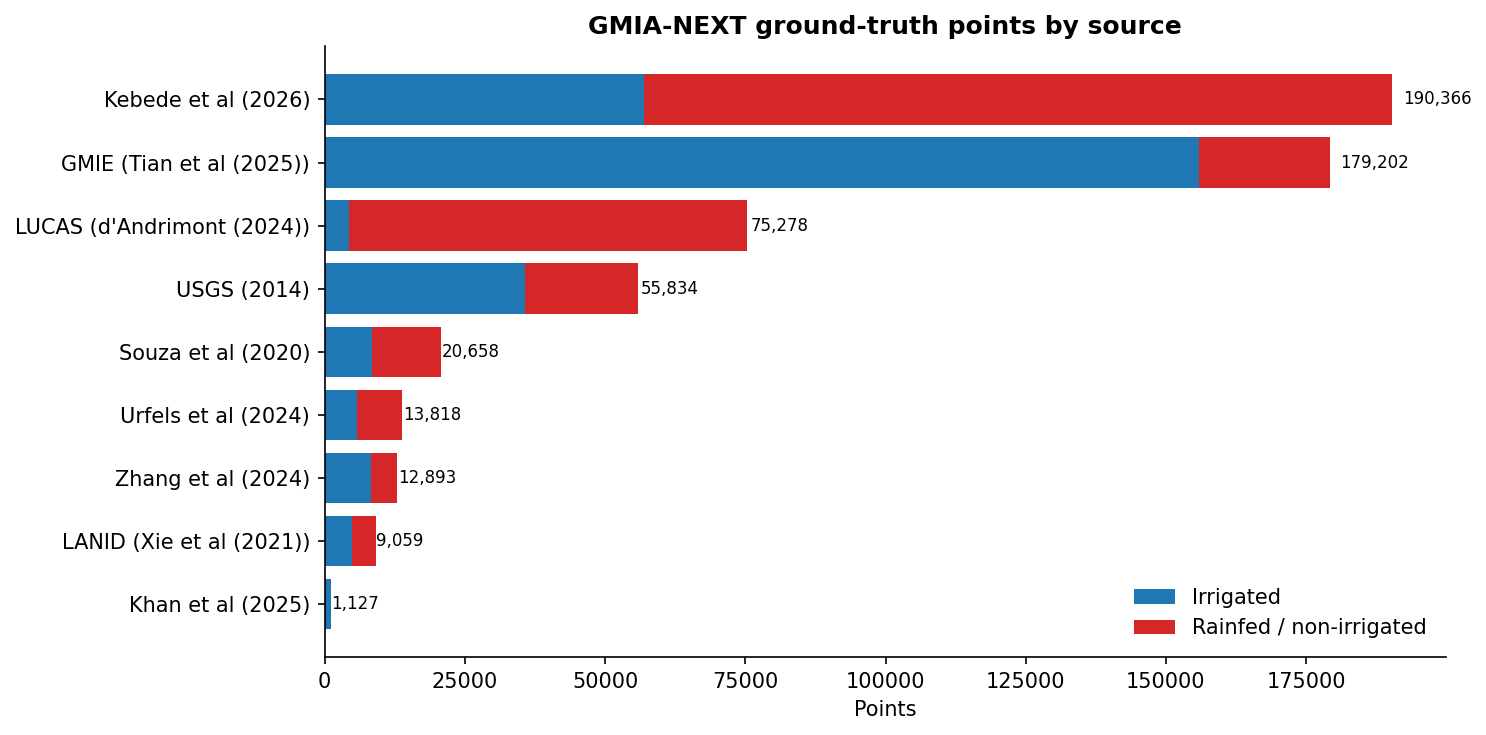

In [7]:
bs = by_source.drop(index="All sources").iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5), dpi=150)
y = np.arange(len(bs))
ax.barh(y, bs["Irrigated"], color=CLASS_COLORS[1], label=CLASS_NAMES[1])
ax.barh(y, bs["Rainfed / non-irrigated"], left=bs["Irrigated"], color=CLASS_COLORS[0], label=CLASS_NAMES[0])
for i, t in enumerate(bs["Total"]):
    ax.text(t * 1.01, i, f"{t:,}", va="center", fontsize=8)
ax.set_yticks(y, bs.index)
ax.set_xlabel("Points")
ax.set_title("GMIA-NEXT ground-truth points by source", fontweight="bold")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save(fig, "global_points_by_source.png")
plt.show()

## A4. Countries and regions

In [8]:
joined = gpd.sjoin(clean, countries[["ISO_A3", "NAME", "WB_REGION", "geometry"]], how="left", predicate="within")
joined = joined[~joined.index.duplicated()]          # a point on a shared border can match two countries
clean["ISO_A3"] = joined["ISO_A3"]
clean["country"] = joined["NAME"]
clean["region"] = joined["WB_REGION"]
print(f"Points inside a country: {clean['country'].notna().sum():,}; outside every polygon (coast, borders): {clean['country'].isna().sum():,}")
print(f"Countries with at least one point: {clean['country'].nunique()}")

# World Bank region codes in this boundary file. "Other" groups high-income countries such as the USA and Canada.
REGION_NAMES = {"AFR": "Sub-Saharan Africa", "MEN": "Middle East & North Africa", "EAP": "East Asia & Pacific",
                "ECA": "Europe & Central Asia", "LAC": "Latin America & Caribbean", "SOA": "South Asia",
                "Other": "Other (incl. USA, Canada)"}
by_region = pd.crosstab(clean["region"].map(REGION_NAMES).fillna("Outside country polygons"), clean["class_name"])
by_region["Total"] = by_region.sum(axis=1)
by_region.sort_values("Total", ascending=False)

Points inside a country: 557,912; outside every polygon (coast, borders): 323
Countries with at least one point: 140


class_name,Irrigated,Rainfed / non-irrigated,Total
region,,,
"Other (incl. USA, Canada)",147159,98336,245495
Latin America & Caribbean,39987,120339,160326
South Asia,22526,17950,40476
East Asia & Pacific,21731,10494,32225
Middle East & North Africa,27974,3908,31882
Europe & Central Asia,6484,22960,29444
Sub-Saharan Africa,15384,2680,18064
Outside country polygons,133,190,323


Saved outputs/gmia/global_points_top_countries.png


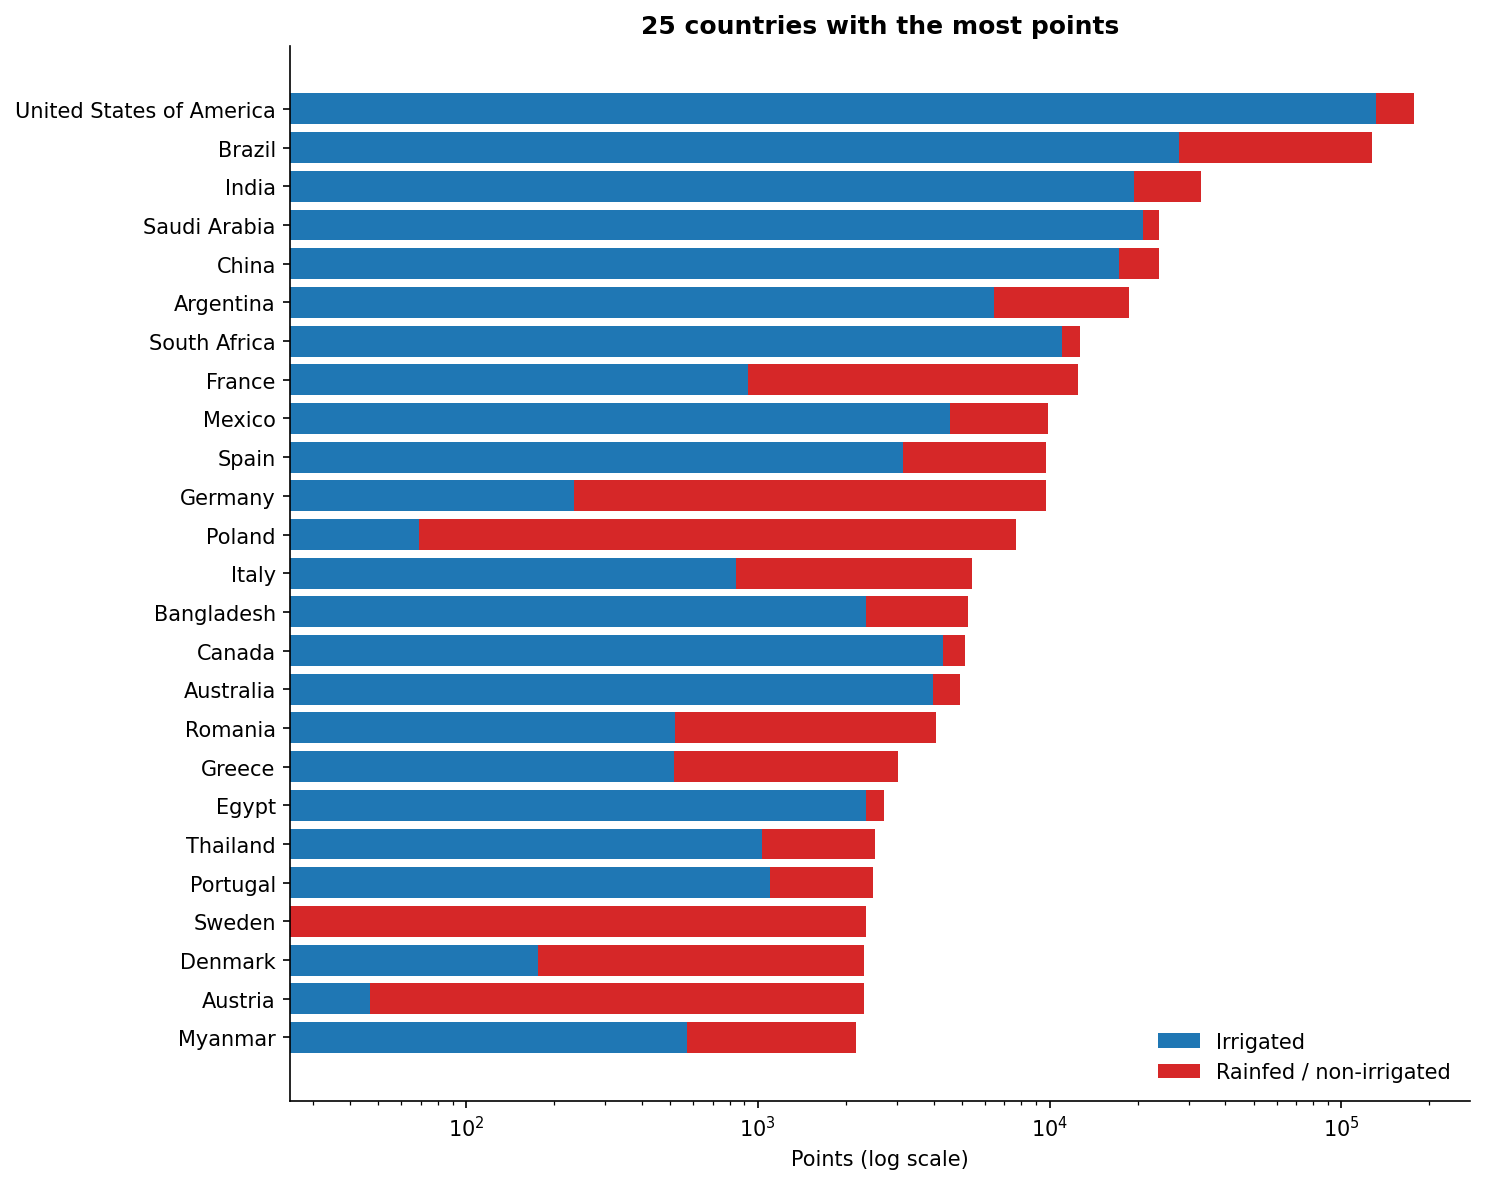

class_name,Irrigated,Rainfed / non-irrigated,Total
country,,,
United States of America,131270,45695,176965
Brazil,27796,99772,127568
India,19514,13390,32904
Saudi Arabia,20900,2866,23766
China,17306,6362,23668
Argentina,6448,12195,18643
South Africa,11057,1649,12706
France,928,11624,12552
Mexico,4547,5352,9899


In [9]:
by_country = pd.crosstab(clean["country"], clean["class_name"]).reindex(columns=[CLASS_NAMES[1], CLASS_NAMES[0]], fill_value=0)
by_country["Total"] = by_country.sum(axis=1)
by_country = by_country.sort_values("Total", ascending=False)

top = by_country.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 8), dpi=150)
y = np.arange(len(top))
ax.barh(y, top[CLASS_NAMES[1]], color=CLASS_COLORS[1], label=CLASS_NAMES[1])
ax.barh(y, top[CLASS_NAMES[0]], left=top[CLASS_NAMES[1]], color=CLASS_COLORS[0], label=CLASS_NAMES[0])
ax.set_xscale("log")
ax.set_yticks(y, top.index)
ax.set_xlabel("Points (log scale)")
ax.set_title("25 countries with the most points", fontweight="bold")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save(fig, "global_points_top_countries.png")
plt.show()
by_country.head(25)

In [10]:
# Middle East & North Africa: the countries closest to our study (Morocco) and transfer (Tunisia) areas.
mena = by_country.loc[clean.loc[clean["region"] == "MEN", "country"].unique()].sort_values("Total", ascending=False)
mena

class_name,Irrigated,Rainfed / non-irrigated,Total
country,,,
Saudi Arabia,20900,2866,23766
Egypt,2349,360,2709
Iraq,1874,214,2088
Libya,771,114,885
Iran,772,110,882
Algeria,702,131,833
Oman,202,24,226
Morocco,133,34,167
Jordan,60,12,72


## A5. Global maps

Saved outputs/gmia/global_points_density.png


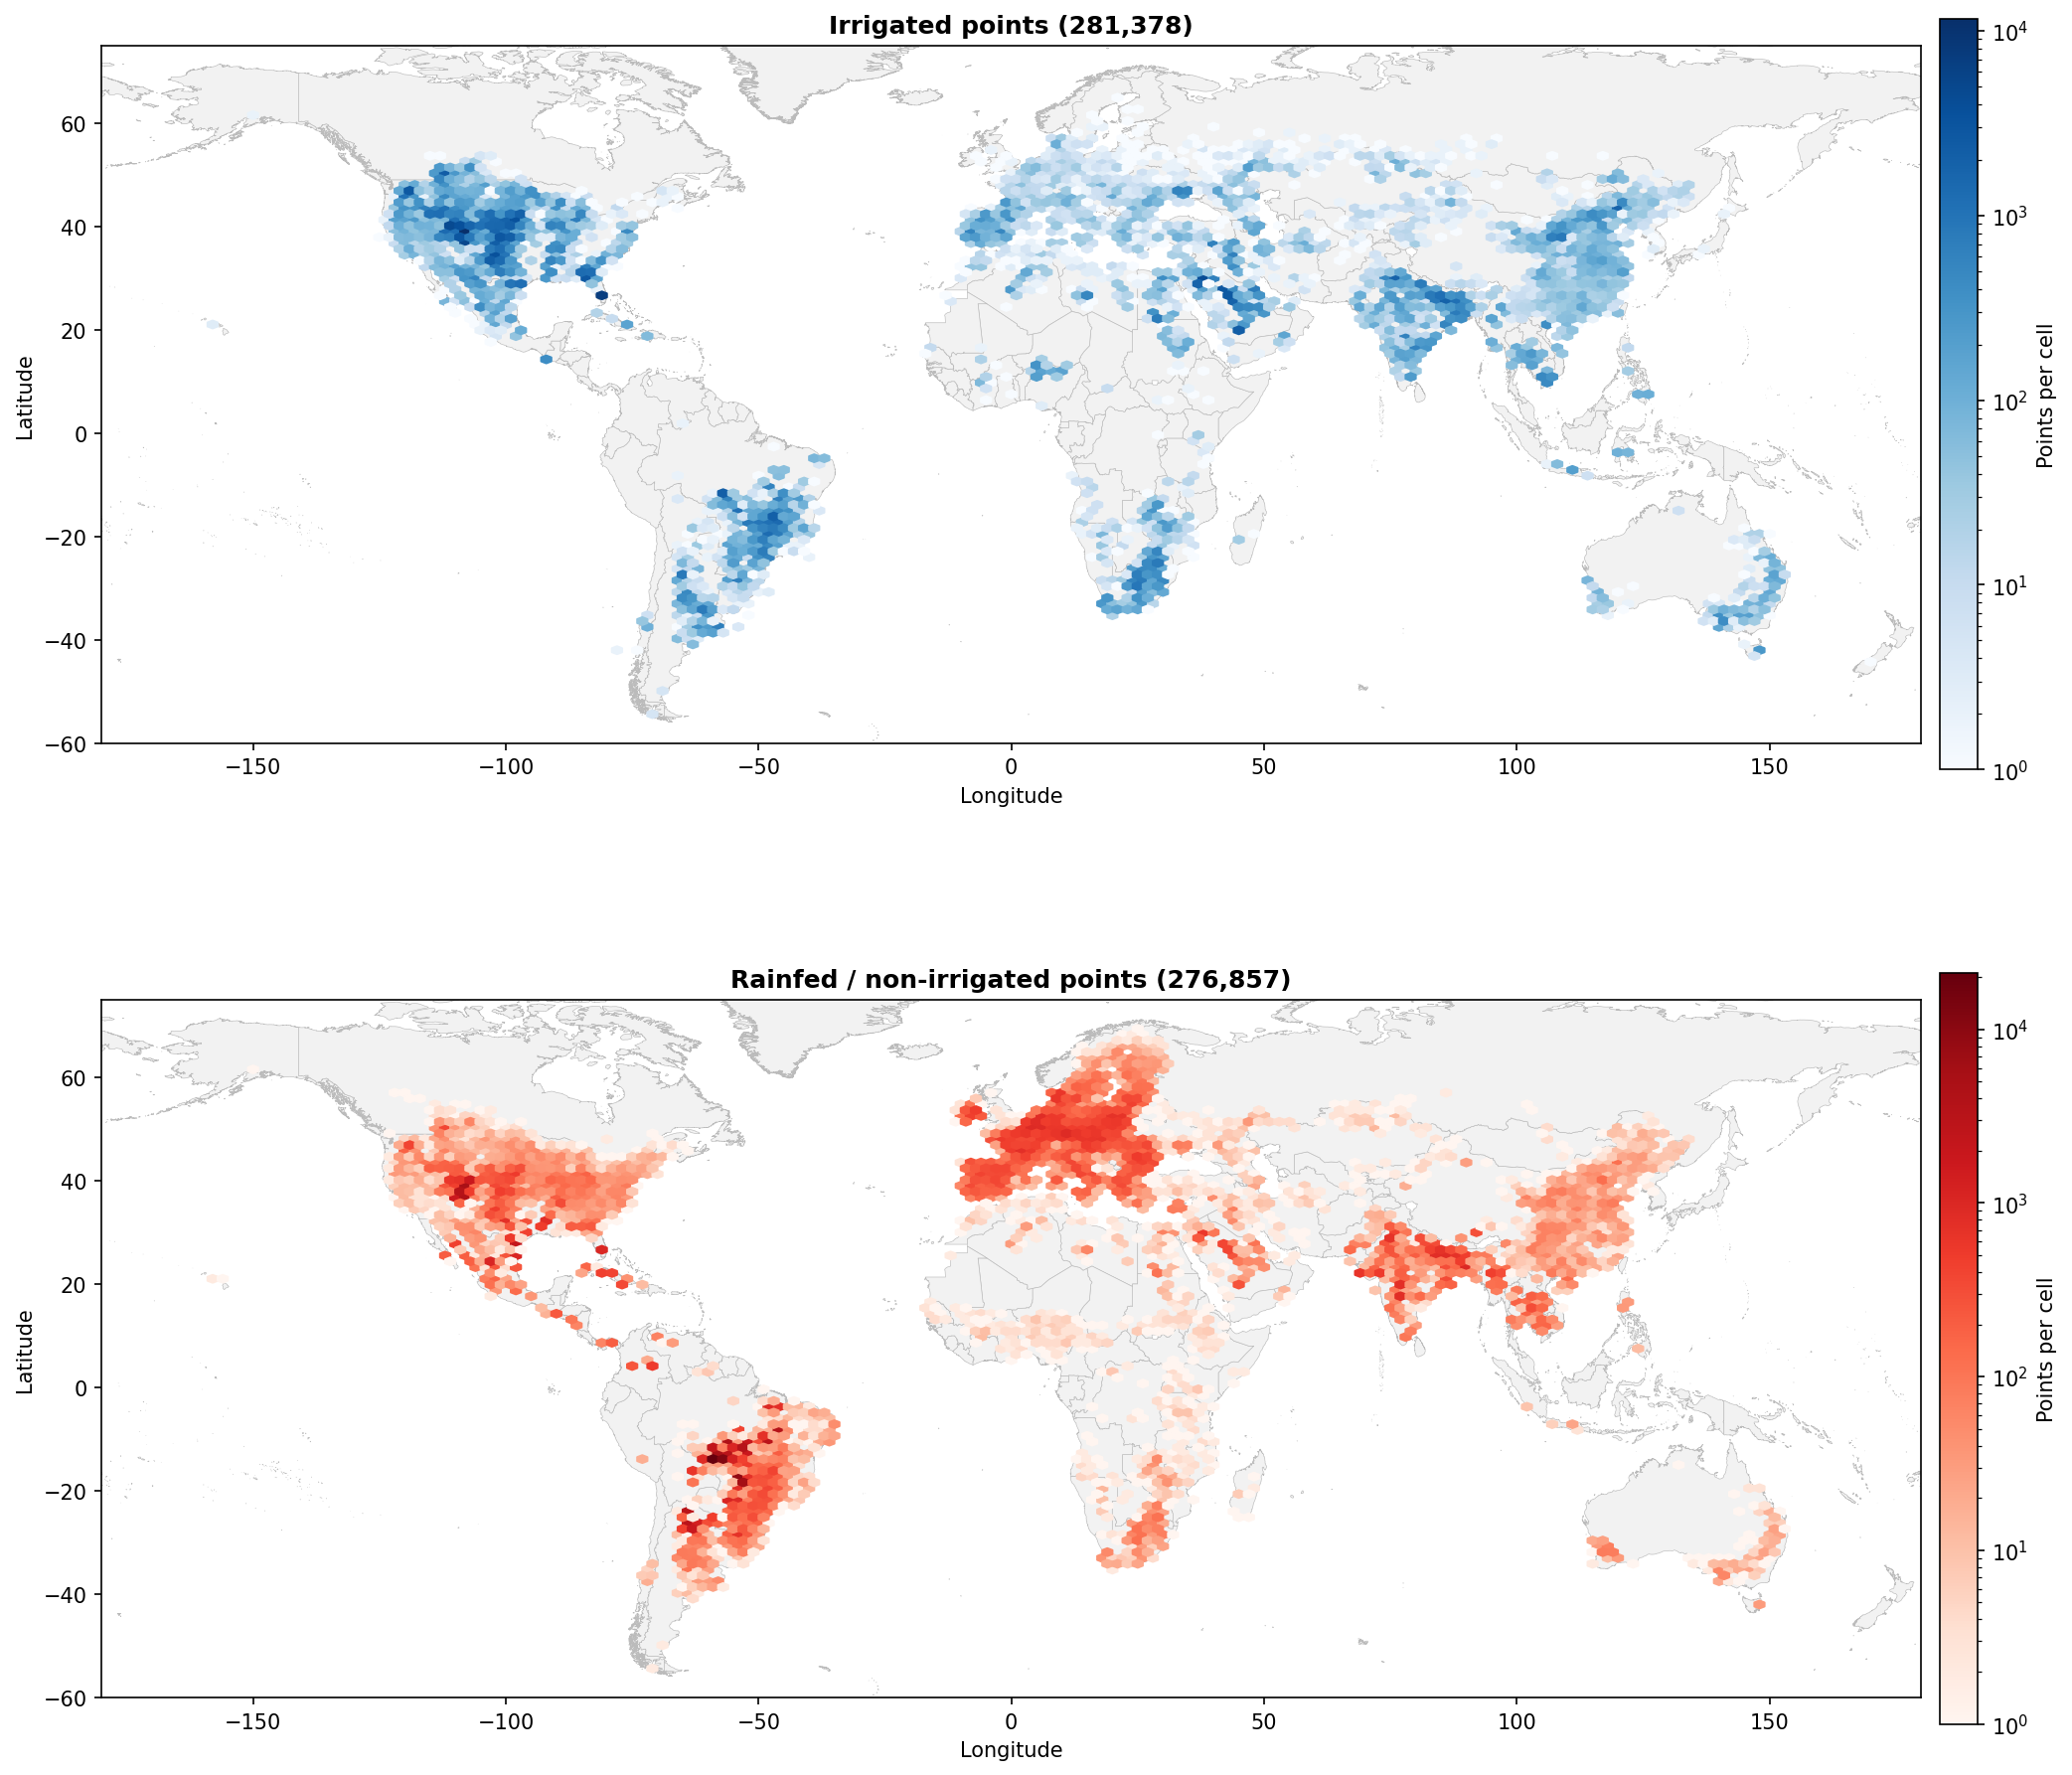

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(14, 13), dpi=150)
for ax, cls in zip(axes, [1, 0]):
    sub = clean[clean["irrigated"] == cls]
    countries.plot(ax=ax, facecolor="#f2f2f2", edgecolor="#bbbbbb", linewidth=0.3)
    hb = ax.hexbin(sub.geometry.x, sub.geometry.y, gridsize=(180, 60), extent=(-180, 180, -60, 75),
                   mincnt=1, norm=LogNorm(), cmap="Blues" if cls == 1 else "Reds")
    fig.colorbar(hb, ax=ax, fraction=0.02, pad=0.01, label="Points per cell")
    ax.set_xlim(-180, 180)
    ax.set_ylim(-60, 75)
    ax.set_title(f"{CLASS_NAMES[cls]} points ({len(sub):,})", fontweight="bold")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
fig.tight_layout()
save(fig, "global_points_density.png")
plt.show()

Saved outputs/gmia/global_points_by_label.png


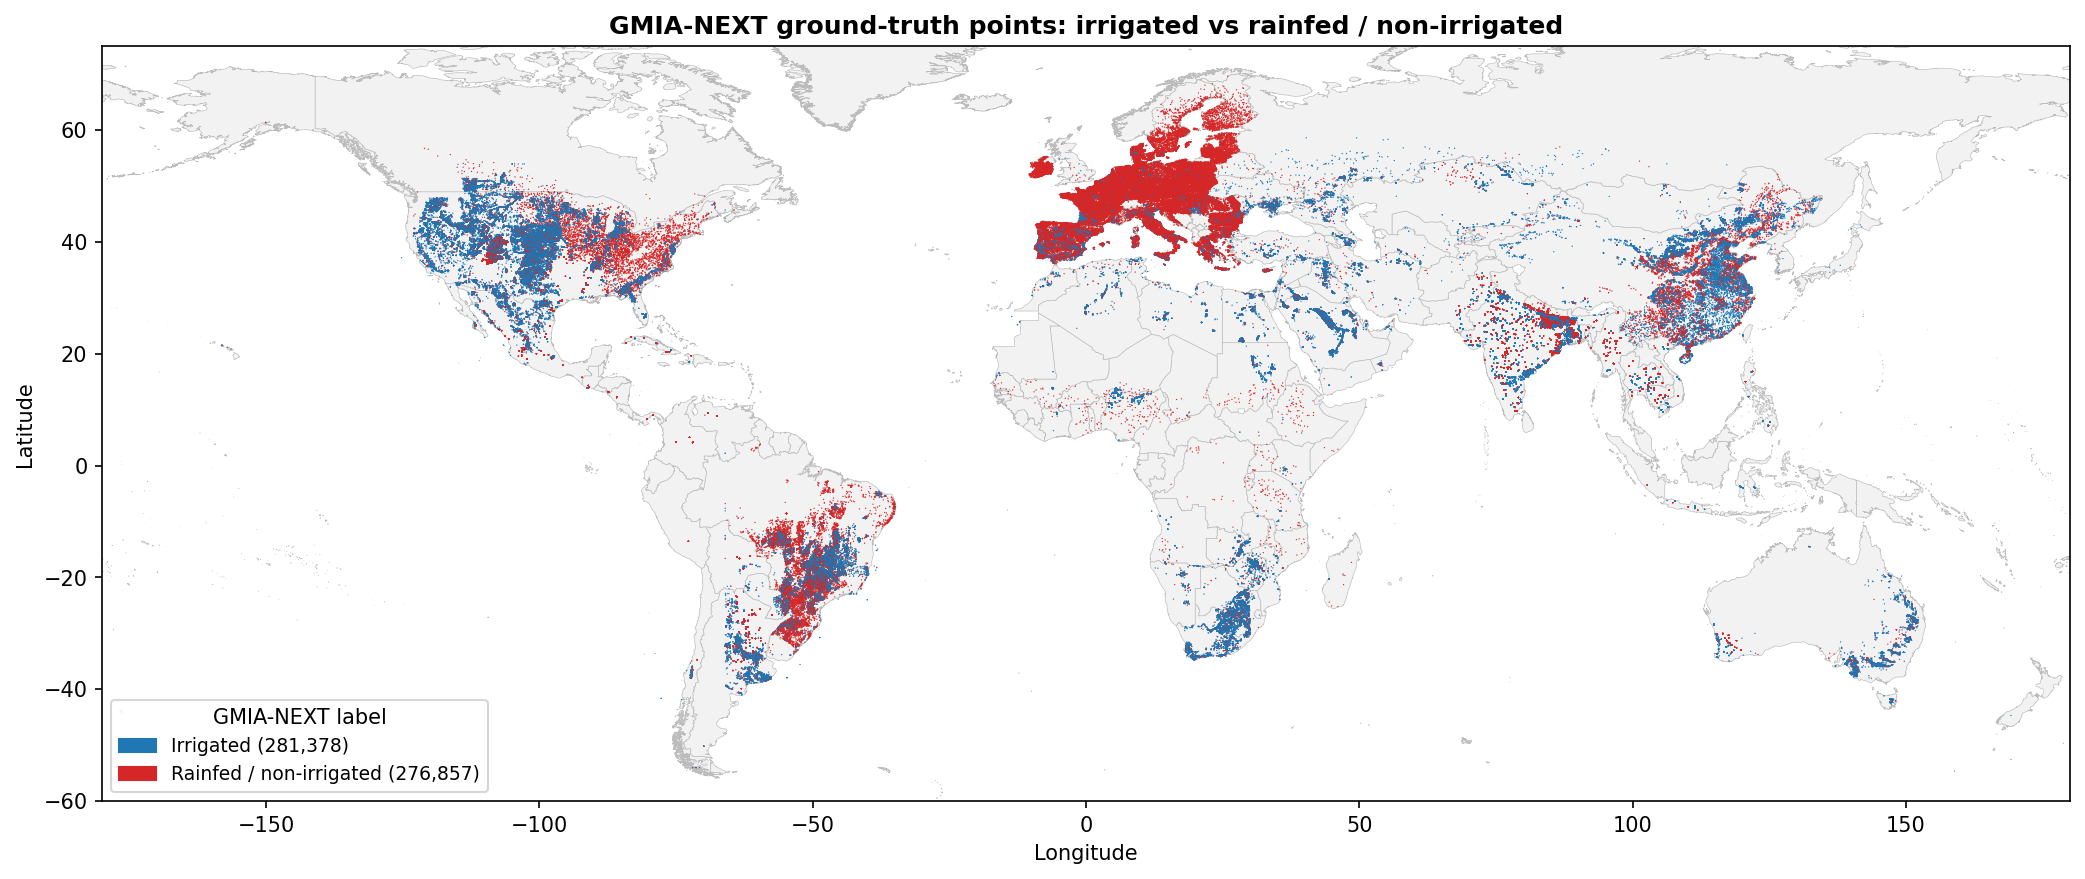

In [12]:
# All points coloured by label. Drawn in random order so neither class hides the other.
order = np.random.default_rng(0).permutation(len(clean))
shuffled = clean.iloc[order]
colors = np.where(shuffled["irrigated"].to_numpy() == 1, CLASS_COLORS[1], CLASS_COLORS[0])

fig, ax = plt.subplots(figsize=(14, 7), dpi=150)
countries.plot(ax=ax, facecolor="#f2f2f2", edgecolor="#bbbbbb", linewidth=0.3)
ax.scatter(shuffled.geometry.x, shuffled.geometry.y, s=0.4, c=colors, linewidths=0, rasterized=True)
n = clean["irrigated"].value_counts()
ax.legend(handles=[Patch(color=CLASS_COLORS[c], label=f"{CLASS_NAMES[c]} ({n[c]:,})") for c in [1, 0]],
          loc="lower left", fontsize=9, title="GMIA-NEXT label")
ax.set_xlim(-180, 180)
ax.set_ylim(-60, 75)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("GMIA-NEXT ground-truth points: irrigated vs rainfed / non-irrigated", fontweight="bold")
fig.tight_layout()
save(fig, "global_points_by_label.png")
plt.show()

# Part B — One country

Everything below uses `COUNTRY_ISO` from the settings cell.

In [13]:
country_poly = countries[countries["ISO_A3"] == COUNTRY_ISO]
assert len(country_poly), f"{COUNTRY_ISO} not found in the World Bank boundaries"
COUNTRY_NAME = country_poly["NAME"].iloc[0]

cp = clean[clean["ISO_A3"] == COUNTRY_ISO].copy()
cp_utm = cp.to_crs(UTM)
cp["x_utm"], cp["y_utm"] = cp_utm.geometry.x, cp_utm.geometry.y

print(f"{COUNTRY_NAME}: {len(cp):,} points after cleaning "
      f"({(pts.to_crs(4326).within(country_poly.union_all())).sum():,} in the raw file)")
t = pd.crosstab(cp["Source"], cp["class_name"], margins=True, margins_name="Total")
t

Morocco: 167 points after cleaning (167 in the raw file)


class_name,Irrigated,Rainfed / non-irrigated,Total
Source,,,
GMIE (Tian et al (2025)),129,24,153
Kebede et al (2026),4,10,14
Total,133,34,167


Saved outputs/gmia/MAR_points_by_label.png


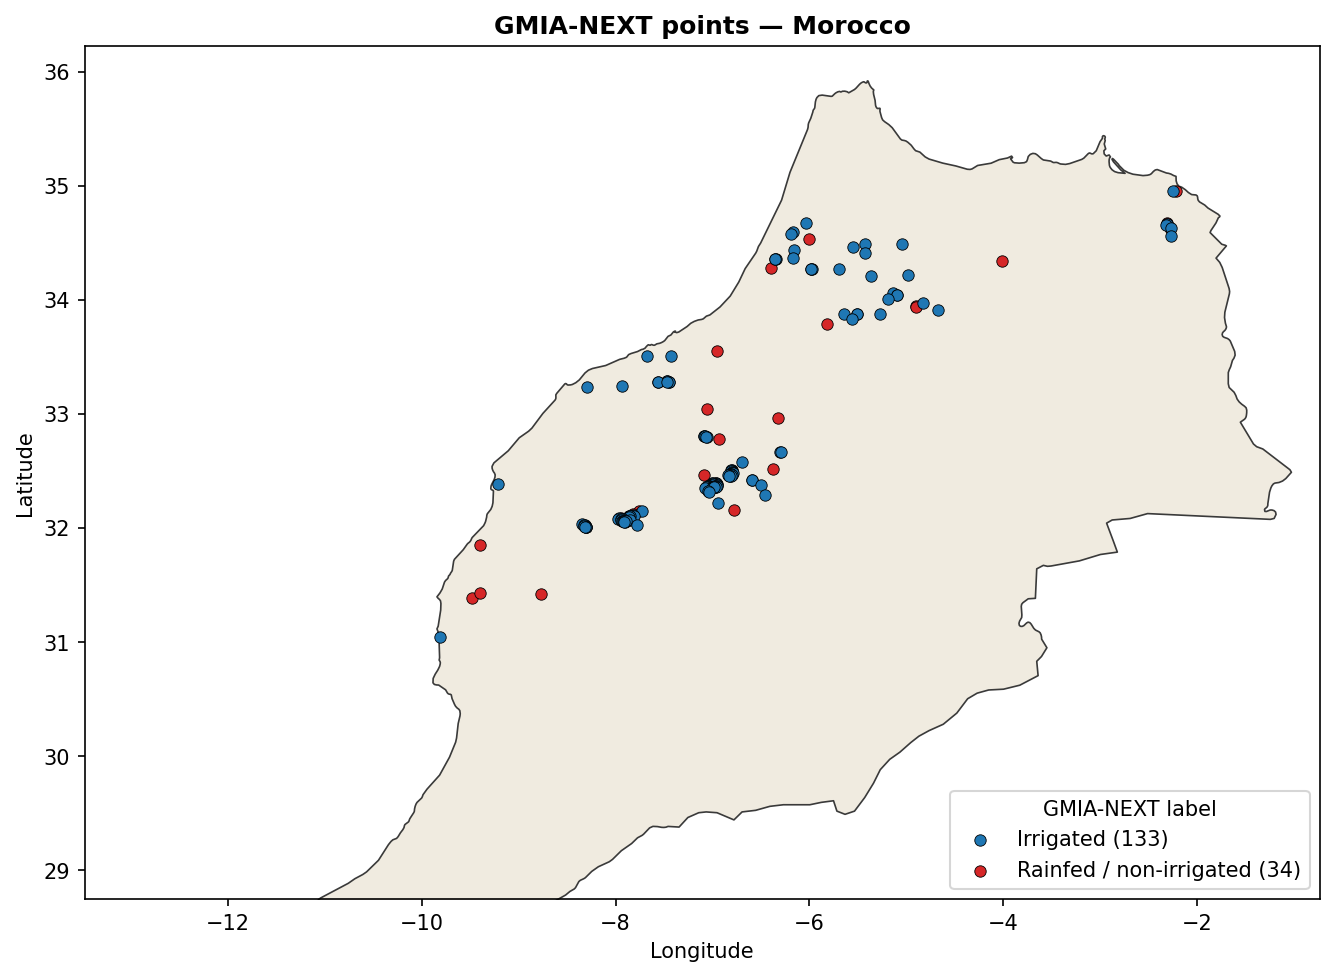

In [14]:
fig, ax = plt.subplots(figsize=(9, 9), dpi=150)
country_poly.plot(ax=ax, facecolor="#f0ebe0", edgecolor="#3a3a3a", linewidth=0.8)
for cls in [0, 1]:
    sub = cp[cp["irrigated"] == cls]
    ax.scatter(sub.geometry.x, sub.geometry.y, s=30, color=CLASS_COLORS[cls], edgecolors="k", linewidths=0.4,
               zorder=3, label=f"{CLASS_NAMES[cls]} ({len(sub)})")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="lower right", title="GMIA-NEXT label")
minx, miny, maxx, maxy = country_poly.total_bounds
ax.set_xlim(minx - 0.3, maxx + 0.3)
ax.set_ylim(max(miny, cp.geometry.y.min() - 2) - 0.3, maxy + 0.3)
ax.set_title(f"GMIA-NEXT points — {COUNTRY_NAME}", fontweight="bold")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
fig.tight_layout()
save(fig, f"{COUNTRY_ISO}_points_by_label.png")
plt.show()

## B2. Spacing between points

How far apart the points are; close points add less independent information to an accuracy estimate.

In [15]:
xy = cp[["x_utm", "y_utm"]].to_numpy()
d, _ = cKDTree(xy).query(xy, k=2)
cp["nn_dist_m"] = d[:, 1]
print("Distance to the nearest other GMIA point (km):")
nn = cp.assign(nn_km=cp["nn_dist_m"] / 1000).groupby("class_name")["nn_km"].describe(percentiles=[0.1, 0.5, 0.9])
nn["count"] = nn["count"].astype(int)
nn.round(2)

Distance to the nearest other GMIA point (km):


,count,mean,std,min,10%,50%,90%,max
class_name,,,,,,,,
Irrigated,133,4.54,9.4,0.07,0.44,0.87,13.84,61.42
Rainfed / non-irrigated,34,12.52,19.0,0.11,0.20,2.33,40.91,77.18


## B3. Overlap with our field survey (Morocco only)

- Distance from each GMIA point to the nearest survey parcel.
- GMIA points that fall **inside** a survey parcel: do the labels agree?
- Which spatial fold (20 km blocks from `2_split_train_test.ipynb`) each point falls in. Points in blocks without any survey parcel lie in areas the models never trained on.

In [16]:
has_survey = COUNTRY_ISO == "MAR" and SURVEY_FILE.exists()
if has_survey:
    survey = gpd.read_file(SURVEY_FILE)
    s_utm = survey.to_crs(UTM)
    sxy = np.c_[s_utm.centroid.x, s_utm.centroid.y]
    dist, idx = cKDTree(sxy).query(xy)
    cp["dist_to_survey_km"] = dist / 1000

    bins = [0, 1, 5, 20, 50, np.inf]
    names = ["< 1 km", "1–5 km", "5–20 km", "20–50 km", "> 50 km"]
    cp["dist_band"] = pd.cut(cp["dist_to_survey_km"], bins=bins, labels=names)
    display(pd.crosstab(cp["dist_band"], cp["class_name"], margins=True, margins_name="Total"))

    inside = gpd.sjoin(cp.drop(columns=[c for c in ["index_right"] if c in cp.columns]),
                       survey[["label", "geometry"]], predicate="within")
    if len(inside):
        inside["survey_class"] = inside["label"].map({1: "Irrigated", 2: "Rainfed"})
        print(f"GMIA points inside a survey parcel: {len(inside)}")
        display(pd.crosstab(inside["class_name"], inside["survey_class"]).rename_axis(index="GMIA", columns="Survey"))
    else:
        print("No GMIA point falls inside a survey parcel.")
else:
    print("Survey comparison skipped (country is not Morocco or the split file is missing).")

class_name,Irrigated,Rainfed / non-irrigated,Total
dist_band,,,
< 1 km,27,3,30
1–5 km,31,4,35
5–20 km,46,13,59
20–50 km,13,5,18
> 50 km,16,9,25
Total,133,34,167


GMIA points inside a survey parcel: 6


Survey,Irrigated
GMIA,
Irrigated,6


In [17]:
if has_survey:
    size = BLOCK_KM * 1000
    cp["block_id"] = (np.floor(cp["x_utm"] / size).astype(int).astype(str) + "_" +
                      np.floor(cp["y_utm"] / size).astype(int).astype(str))
    block_fold = survey.drop_duplicates("block_id").set_index("block_id")["fold"]
    cp["survey_fold"] = cp["block_id"].map(block_fold)
    cp["fold_label"] = cp["survey_fold"].map(lambda f: "no survey parcels in block" if pd.isna(f) else f"fold {int(f)}")
    display(pd.crosstab(cp["fold_label"], cp["class_name"], margins=True, margins_name="Total"))

class_name,Irrigated,Rainfed / non-irrigated,Total
fold_label,,,
fold 0,9,4,13
fold 1,2,0,2
fold 2,58,13,71
fold 3,11,0,11
fold 4,18,1,19
no survey parcels in block,35,16,51
Total,133,34,167


## B4. Land cover at the points (ESA WorldCover 2021)

GMIA label 0 means rainfed **or non-irrigated**, so some 0-points may not be cropland at all. WorldCover at each point shows how many sit on cropland. The local WorldCover file covers Morocco only.

In [18]:
WC_NAMES = {10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland", 50: "Built-up",
            60: "Bare / sparse", 70: "Snow / ice", 80: "Water", 90: "Herbaceous wetland", 95: "Mangroves", 100: "Moss / lichen"}
if WORLDCOVER_FILE.exists():
    with rasterio.open(WORLDCOVER_FILE) as src:
        b = src.bounds
        inside_r = (cp.geometry.x.between(b.left, b.right) & cp.geometry.y.between(b.bottom, b.top)).to_numpy()
        vals = np.zeros(len(cp), dtype=int)
        if inside_r.any():
            coords = list(zip(cp.geometry.x[inside_r], cp.geometry.y[inside_r]))
            vals[inside_r] = [v[0] for v in src.sample(coords)]
    cp["worldcover"] = pd.Series(vals, index=cp.index).map(WC_NAMES).fillna("outside raster")
    display(pd.crosstab(cp["worldcover"], cp["class_name"], margins=True, margins_name="Total"))
else:
    print("WorldCover file not found; skipped.")

class_name,Irrigated,Rainfed / non-irrigated,Total
worldcover,,,
Cropland,95,17,112
Grassland,7,4,11
Shrubland,18,5,23
Tree cover,13,8,21
Total,133,34,167


## B5. Save the country points

Cleaned points (duplicates and conflicting labels removed) with the checks as columns. For Morocco these can serve as an **independent test set**: a different team, a different sampling design, the same 2023/24 season as the 2024 imagery. Use them only for evaluation, not for training.

In [19]:
cols = [c for c in ["x", "y", "irrigated", "class_name", "Source", "nn_dist_m", "dist_to_survey_km",
                    "survey_fold", "worldcover", "geometry"] if c in cp.columns]
out = cp[cols].rename(columns={"x": "lon", "y": "lat"}).copy()
out_file = OUT_DIR / f"gmia_points_{COUNTRY_ISO}.geojson"
out_file.write_text(out.to_json(drop_id=True))
by_source.to_csv(OUT_DIR / "global_points_by_source.csv")
by_country.to_csv(OUT_DIR / "global_points_by_country.csv")
print(f"Saved {out_file.relative_to(ROOT)} ({len(out):,} points)")

Saved outputs/gmia/gmia_points_MAR.geojson (167 points)


## Key findings

**Global file (v0)**
- The file holds **601,972 points** (283,352 irrigated, 318,620 rainfed), not the 380,696 stated in the README. Quote the file numbers, or the cleaned ones below, and cite the dataset as v0.
- Souza et al. (2020, Brazil, 20,658 points) has `long` / `lat` columns set to 0; the point geometry is correct. Always take coordinates from the geometry.
- 43,439 points are extra copies at an existing location, almost all from Urfels et al. (2024; 75% of its points). 298 locations carry both labels; their 750 points were dropped.
- After cleaning: **558,235 points**, 281,378 irrigated and 276,857 rainfed, in 140 countries. Two sources (Kebede et al. 2026, GMIE) supply two thirds of them. The USA (177k) and Brazil (115k) dominate; Africa is thin outside South Africa and Egypt.
- North Africa: Morocco 167, Tunisia 54, Algeria 833, Libya 885, Egypt 2,709.

**Morocco**
- **167 points**: 133 irrigated, 34 rainfed / non-irrigated. 153 come from GMIE, 14 are new GMIA-NEXT points (10 of them rainfed).
- They spread further than our survey: rainfed points near Tadla, El Haouz, Gharb, Saïss and eastern Morocco, where the survey has no rainfed parcels.
- 6 points fall inside survey parcels; all 6 agree (irrigated).
- 51 points (35 irrigated, 16 rainfed) lie in 20 km blocks with no survey parcel. These test the models in areas they have never seen. The other 116 sit in blocks of the survey folds, mostly fold 2.
- Only 112 of 167 points (67%) are on WorldCover cropland, and only 17 of the 34 rainfed points. Label 0 means rainfed **or non-irrigated**, so some 0-points may be grassland, shrubland or orchards that WorldCover calls tree cover. Check those points on imagery before using them, or score only the cropland points.
- Points are often close together (median 0.9 km between irrigated points), so the effective sample is smaller than 167. Report accuracy with confidence intervals.

**Use in this study**: an independent test set for Morocco (evaluation only, never training), reported for all points and for the 51 points outside survey blocks.